# Prepare auditable data for a frontier policy

**Question:** How do frozen partitions and train-only normalization make a synthetic scheduling experiment reproducible without exposing held-out cases?

**Level:** 2 : Method in practice.

**Prerequisites:** Read the case-index and split-design lessons. **Estimated time:** 45 minutes.

## Objectives

By the end, you can trace a generated graph from its seed and family through a frozen split record; inspect why seed, family, and product-case separation answer different leakage risks; fit named feature statistics on training records only; and reproduce the digest that binds those statistics to the source rows. You will also quantify how family and size alter the feature population. The exercise uses the repository's production data contracts on a small, deliberately bounded subset so it remains quick to run. It teaches data preparation, not policy training or model quality. A correct digest proves byte-level reproducibility for the declared inputs; it does not establish that synthetic graphs represent any operating mine.

## Setup

Run from the repository root with the pinned notebook environment. The source generator, partition builder, validator, and normalizer are imported from the data pipeline; the cells below do not copy their algorithms. The committed split ledger is the authority for the candidate experiment, while a compact prefix of its training rows is used here to keep the lesson practical. Validation and test rows are inspected as metadata only. They are never passed to the fitting call. The two package pins below match the notebook environment. Execute the whole notebook in a fresh kernel so that the printed counts and plots are regenerated from the frozen source files.

```bash
python -m pip install numpy==2.5.1 matplotlib==3.11.2
```

### Package versions

The next cell reports installed pins before data processing.

### Report exact runtime pins before the workflow begins.

In [1]:
# Report exact runtime pins before the workflow begins.
# Report exact runtime pins before processing data.
import importlib.metadata
print({name: importlib.metadata.version(name) for name in ('numpy', 'matplotlib')})

{'numpy': '2.5.1', 'matplotlib': '3.11.2'}


### Import the committed engine APIs; this lesson does not reproduce their algorithms.

In [2]:
# Import the committed engine APIs; this lesson does not reproduce their algorithms.
from pathlib import Path
import json
import sys
import numpy as np
import matplotlib.pyplot as plt
ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'VERSION').is_file()
    and (path / 'data-pipeline' / 'pipeline').is_dir()
)
sys.path.insert(0, str(ROOT / 'data-pipeline'))
from pipeline.model.frontier_data import (
    FEATURE_NAMES, GENERATOR_VERSION, generate_graph
)
from pipeline.model.frontier_features import (
    fit_training_normalizer, normalizer_contract, feature_contract_sha256
)
from pipeline.model.frontier_policy import validate_split_manifest
from pipeline.model.frontier_splits import build_split_manifest, manifest_sha256

## Data

Each generator row declares exactly four fields: an integer seed, a graph family, a node count, and a generator version. The seed determines the pseudo-random stream; the family determines the precedence pattern; and the size determines the number of decision nodes. A graph then supplies seven named node features alongside resource vectors and precedence edges. The generator is deterministic for the same seed, family, size, periods, and implementation version. These records are synthetic method-development cases. They are not mine plans, MineLib instances, customer data, or evidence of operational performance. The product benchmark case identifiers are kept separately by the frozen ledger and are excluded from every fitting and model-selection split.

The split policy intentionally changes graph family between training, validation, and test. This asks the later evaluation to measure transfer across structures rather than merely memorization of nearby random seeds. Different seed ranges prevent exact random-stream reuse, while different family assignments provide a stronger structural separation. The product case set is sealed as an evaluation-only list; it must not influence normalizer fitting, training choices, or validation-based selection. Read the manifest before changing it: changing a family, seed, size rule, generator version, or case list changes the scientific question and should produce a new versioned receipt.

### Validate the frozen split and inspect the versioned release-receipt fields.

In [3]:
# Validate the frozen split and inspect the versioned release-receipt fields.
index = json.loads((ROOT / 'data/derived/manifests/index.json').read_text(encoding='utf-8'))
manifest = build_split_manifest([row['case_id'] for row in index['cases']])
partition_counts = validate_split_manifest(manifest)
manifest_digest = manifest_sha256(manifest)
print({'generator': GENERATOR_VERSION, 'counts': partition_counts, 'manifest_sha256': manifest_digest})
receipt_schema = json.loads((ROOT / 'docs/contracts/schemas/frontier-release.schema.json').read_text(encoding='utf-8'))
case_schema = receipt_schema['$defs']['case']
print({'receipt_fields': receipt_schema['required'],
       'case_fields': case_schema['required'],
       'case_statuses': case_schema['properties']['status']['enum']})

{'generator': 'frontier-graphs/1.0.0', 'counts': {'train': 1000, 'validation': 200, 'test': 500, 'product_cases': 13}, 'manifest_sha256': '18860c8a361576ba924ec95fd5dfe9d58c8a37a3466a1c17bb9765ddfc81350c'}
{'receipt_fields': ['schema', 'created_at_utc', 'product_version', 'engine_version', 'source_commit', 'training_source_commit', 'checkpoint_sha256', 'checkpoint_members_sha256', 'feature_contract_sha256', 'split_sha256', 'training_split_sha256', 'case_index_sha256', 'baseline', 'cases', 'summary', 'redistribution'], 'case_fields': ['case_id', 'product_version', 'engine_version', 'source_commit', 'checkpoint_sha256', 'feature_contract_sha256', 'status', 'failure_reason'], 'case_statuses': ['complete', 'partial', 'failed', 'unavailable']}


## Method

First, load the committed case index and rebuild the approved split manifest through the engine API. The validator checks that the lists are well formed and disjoint. Then sample only a small training prefix and inspect its generated graphs. The normalizer API consumes the row records, regenerates their feature matrices, and fits means and scales using those training values alone.

For feature j, a stored standardized value is zᵢⱼ = (xᵢⱼ − μⱼ) / σⱼ. The mean and scale are computed over nodes from the training rows only. A constant feature is handled by the implementation's explicit scale guard. The training-data digest hashes each seed and the exact contiguous little-endian float32 feature bytes in row order. A second canonical JSON digest binds that data digest to the named normalizer contract. This makes changes in row order, seed, generated feature values, feature names, or fitted statistics visible. It is an integrity receipt, not a cryptographic claim about the scientific validity of the generator.

The API rejects an empty training set, duplicate seeds, a mismatched row schema, non-training split labels, and feature names that introduce identifiers or outcomes. The frozen manifest itself carries the full 1,000/200/500 partition sizes; fitting the full training partition is part of the separate training run. The lesson fits only 24 training rows to limit runtime. Its small-sample statistics are for understanding the pipeline and must never replace the full-run normalizer or be reported as trained-model evidence.

$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$

$$h = \mathrm{SHA256}(\mathrm{canonicalJSON}(\mathrm{normalizer}, h_{train}))$$

### Generate only a small training sample so validation and test values remain untouched.

In [4]:
# Generate only a small training sample so validation and test values remain untouched.
families = sorted({item['family'] for item in manifest['train']})
sample_rows = []
for family in families:
    family_rows = [row for row in manifest['train'] if row['family'] == family]
    sample_rows.extend(family_rows[:12])
sample_graphs = [
    generate_graph(row['seed'], row['family'], row['size'])
    for row in sample_rows
]
family_sizes = {
    family: [graph.size for graph in sample_graphs if graph.family == family]
    for family in sorted({graph.family for graph in sample_graphs})
}
print({
    name: (len(values), min(values), max(values))
    for name, values in family_sizes.items()
})

{'benched': (12, 32, 76), 'branching': (12, 2066, 2110)}


### Plot the sampled training graph sizes by their declared structure.

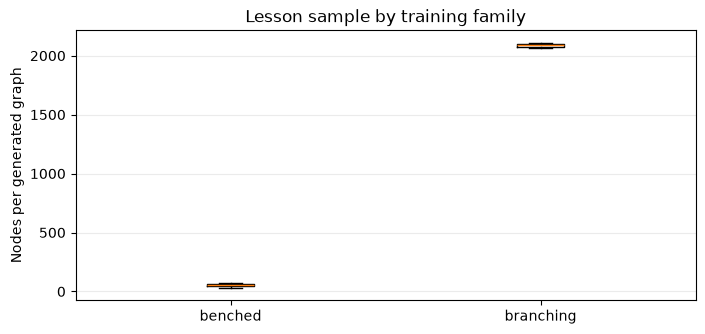

In [5]:
# Plot the sampled training graph sizes by their declared structure.
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot([values for values in family_sizes.values()], tick_labels=list(family_sizes))
ax.set_ylabel('Nodes per generated graph')
ax.set_title('Lesson sample by training family')
ax.grid(axis='y', alpha=.25)
plt.show()

### Reading the family-size figure

The chart shows the node-count range generated by the small, fixed seed sample, grouped by family. Distinct ranges reflect the sampling rule, not a learned-policy result. Family labels encode different precedence structures, so later evaluation across them tests structural transfer rather than random variation alone. The subset is illustrative; use the manifest counts as the protocol, not this plot, when describing the approved experiment.

### Fit the named normalizer on training rows and bind its statistics to source bytes.

In [6]:
# Fit the named normalizer on training rows and bind its statistics to source bytes.
normalizer, training_data_digest = fit_training_normalizer(sample_rows)
normalizer_data = normalizer_contract(normalizer)
feature_digest = feature_contract_sha256(normalizer, training_data_digest)
receipt = {'rows_used': len(sample_rows), 'node_rows': normalizer.train_rows}
receipt['training_data_sha256'] = training_data_digest
receipt['feature_contract_sha256'] = feature_digest
print(receipt)
print(normalizer_data)

{'rows_used': 24, 'node_rows': 25704, 'training_data_sha256': '32682a68de357b1f7c513d7ca18a948cd14510550b4d0634c15b0d42e32b2692', 'feature_contract_sha256': 'c03e5084fae8018041a56c98e6eb99f169afd5da5efe2b11fee54ed6a8557ce7'}
{'schema_version': '1.0.0', 'feature_names': ['value_norm', 'tonnage_norm', 'plant_use_fraction', 'grade_norm', 'depth_fraction', 'predecessor_count', 'successor_count'], 'mean': [-0.06779935832860992, 0.3312809572943828, 0.5, 0.3901734461507073, 0.8136300120069079, 0.543864768129474, 0.36890497736092526], 'scale': [0.20125175989155722, 0.12597317052175888, 0.5, 0.19661334310334042, 0.14608429783929, 0.14777271521878518, 0.3762753789774591], 'train_rows': 25704, 'sha256': 'cf476a6419aa178dbf03c5e8dbcd3d3a0b52d9fe7c14b7f696b3903fe28a1fd3'}


### Apply the public named-feature transformation and check finiteness.

In [7]:
# Apply the public named-feature transformation and check finiteness.
raw = np.concatenate([graph.node_features for graph in sample_graphs], axis=0)
scaled = normalizer.transform(raw, FEATURE_NAMES)
print('feature order:', list(FEATURE_NAMES))
print('raw shape:', raw.shape, 'scaled finite:', bool(np.isfinite(scaled).all()))

feature order: ['value_norm', 'tonnage_norm', 'plant_use_fraction', 'grade_norm', 'depth_fraction', 'predecessor_count', 'successor_count']
raw shape: (25704, 7) scaled finite: True


### Compare raw and standardized values without implying distribution alignment.

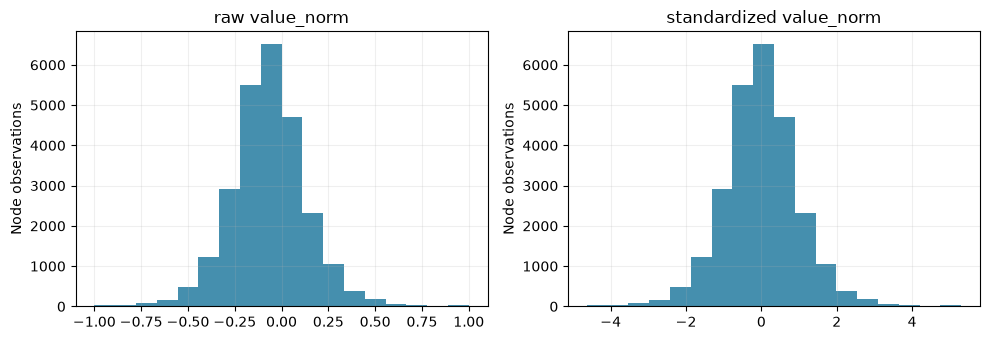

In [8]:
# Compare raw and standardized values without implying distribution alignment.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
series = ((raw[:, 0], 'raw value_norm'), (scaled[:, 0], 'standardized value_norm'))
for axis, (values, title) in zip(axes, series):
    axis.hist(values, bins=18, color='#247ba0', alpha=.85)
    axis.set_title(title)
    axis.set_ylabel('Node observations')
    axis.grid(alpha=.2)
plt.tight_layout()
plt.show()

### Reading the feature-scale figure

Each panel displays the same feature under raw and training-standardized scales. Centering and scaling are fitted only on the small training subset, and the vertical axis shows node observations, not independent mines. The shape remains informative after scaling, which is why normalization must not be described as distribution alignment. Held-out families may still differ substantially from the training population.

### Diagnostic views

Three views answer different data questions. The first compares node counts by family in a small deterministic sample, showing why a family label carries structural meaning. The second compares raw and standardized feature distributions for the lesson subset; centering and scaling can make numerical ranges easier for an optimizer, but it does not remove distribution shift. The third varies graph size while holding family and seed fixed, making size-related feature behavior visible.

The measured sample is intentionally not a benchmark and has no outcome labels. A plot that looks balanced is not proof that the full generator is balanced. Likewise, standardization does not make validation and test observations exchangeable with training. Their families are deliberately different, so a later performance drop can reflect structural transfer difficulty. The right response is to report it and inspect failure modes, not to refit on held-out data.

### Vary size at fixed family and seed to inspect generator sensitivity.

In [9]:
# Vary size at fixed family and seed to inspect generator sensitivity.
size_rows = [
    generate_graph(seed, 'branching', size)
    for size in (32, 96, 256)
    for seed in (71, 72, 73)
]
size_summary = [
    (graph.size, float(graph.node_features[:, 4].mean()),
     float(graph.node_features[:, 5].mean()))
    for graph in size_rows
]
print('size, mean depth fraction, mean predecessor fraction:', size_summary[:3])

size, mean depth fraction, mean predecessor fraction: [(32, 0.643750011920929, 0.515625), (32, 0.643750011920929, 0.515625), (32, 0.643750011920929, 0.5)]


### Visualize the size response for the declared depth feature.

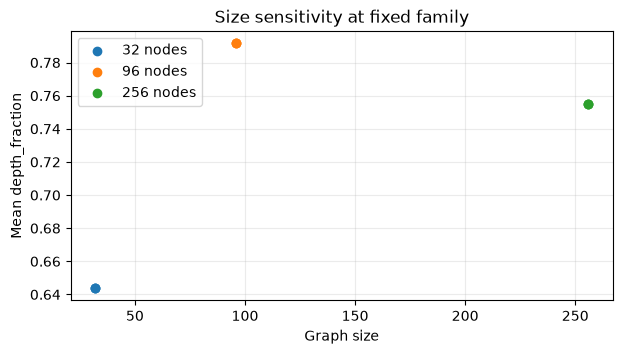

In [10]:
# Visualize the size response for the declared depth feature.
fig, ax = plt.subplots(figsize=(7, 3.5))
for size in (32, 96, 256):
    rows = [row for row in size_summary if row[0] == size]
    ax.scatter([size] * len(rows), [row[1] for row in rows], label=f'{size} nodes')
ax.set_xlabel('Graph size')
ax.set_ylabel('Mean depth_fraction')
ax.set_title('Size sensitivity at fixed family')
ax.grid(alpha=.25)
ax.legend()
plt.show()

### Reading the size-sensitivity figure

The graph family is fixed to branching; seeds 71, 72 and 73 are paired across sizes 32, 96 and 256. The figure plots only mean depth fraction as three points per size; mean predecessor fraction is printed in the preceding output. The observed depth means are about 0.644, 0.792 and 0.755, so the response is non-monotone and the three seeds overlap. This is a generator sensitivity view, not a model-quality test. A real deposit can have structures outside these patterns, so size alone cannot establish representativeness.

### Repeat fitting at smaller training counts and retain the frozen manifest digest.

In [11]:
# Repeat fitting at smaller training counts and retain the frozen manifest digest.
for count in (8, 24):
    fitted, digest = fit_training_normalizer(manifest['train'][:count])
    report = {'training_graphs': count, 'node_rows': fitted.train_rows}
    report['mean_value_norm'] = round(float(fitted.mean[0]), 5)
    report['data_sha256_prefix'] = digest[:12]
    print(report)
print('Frozen manifest remains:', manifest_digest)

{'training_graphs': 8, 'node_rows': 368, 'mean_value_norm': -0.04913, 'data_sha256_prefix': '4dd2bab9cce9'}
{'training_graphs': 24, 'node_rows': 1881, 'mean_value_norm': -0.10564, 'data_sha256_prefix': '83c5c5bc44c0'}
Frozen manifest remains: 18860c8a361576ba924ec95fd5dfe9d58c8a37a3466a1c17bb9765ddfc81350c


## Results

**Answer:** The frozen ledger records 1,000 training, 200 validation, and 500 test rows. The printed table reports the frozen partition counts, unique seeds, family membership, the bounded lesson sample, the number of nodes used to fit its normalizer, and the two reproducibility digests. The table is the answer to the notebook question: preparation is auditable because the row schema, partition policy, train-only fitting boundary, and content hashes are explicit and independently checked. It does not say that the policy has learned a useful scheduling rule.

The feature summary reports the fitted mean and scale by declared name. These values describe only the 24-row lesson subset. If you increase the subset size, the statistics and training-data digest should change while the frozen partition manifest digest stays fixed. Regenerating with the same files, order, and subset should reproduce the same output. This distinction helps diagnose whether a difference came from a changed protocol or simply from the deliberately smaller sample used in this tutorial.

### Release evidence contract

A release receipt closes the provenance chain only after the frozen policy has been evaluated on every declared product case. Its top-level fields bind product and engine versions, training and evaluation commits, five ordered checkpoint hashes, the feature contract, split, case index, baseline identity, all thirteen outcomes, and redistribution limits. A scheduled case carries a trace digest; a failed or unavailable case carries a reason. The schema checks field shape and conditional requirements. The Python validator additionally reconciles case identity, ordering, shared versions and commits, paired objectives, and status totals. A valid JSON document alone does not prove that these links agree. The consumed one-shot sample is a historical attempt and remains excluded. The later, disjoint 500-seed test and thirteen-case evaluation have separate retained receipts. This lesson inspects the contract; the held-out analysis and its summary validator are covered separately.

$$h_{members}=\mathrm{SHA256}(h_1\Vert h_2\Vert h_3\Vert h_4\Vert h_5)$$

A scheduled case carries a trace digest; a failed case carries an explicit reason.

### Sensitivity and limits

Change the family and size in the final comparison cell and inspect whether the node-feature distributions move. Repeat the normalizer fit with 8, 24, and 48 training rows, then compare feature means and the data digest. These are sensitivity checks on the preprocessing population, not hyperparameter selection: do not choose the subset because it produces attractive downstream results. The approved full run uses the complete frozen training list.

The generated families encode a small set of synthetic precedence patterns and simple economic/resource relationships. They do not model geotechnical uncertainty, fleet interactions, detailed block models, changing prices, or human operational constraints. The normalizer only rescales features; it cannot repair a weak generator or leakage in a target. Seed disjointness is not enough by itself if generated cases share structure, which is why this protocol also partitions graph families. Family separation is a deliberate stress test, not a claim that the families span real deposits. A robust conclusion needs the later held-out experiments, uncertainty intervals, failure accounting, and authentic product cases under the approved evaluation design.

These partitions answer different questions. Holding out seeds tests dependence on one pseudo-random stream; holding out graph families tests transfer to different precedence structures; a real-data study would also need to hold out whole deposits when observations share a mine identity. This synthetic protocol supports only the first two questions and cannot establish transfer to operating mines. The normalizer is fitted on training rows and then applied unchanged. PPO optimization and checkpoint selection use training and validation data; the test partition stays sealed until the ensemble is frozen.

### Use your own data

Use this lesson to understand the interface, not to paste an operational dataset into the synthetic generator. The current row schema requires a seed, family, size, and generator version; real block models do not become valid observations by assigning them those fields. A real-data workflow needs its own documented source, rights and consent, schema mapping, missingness rules, units, split unit, and independent validation. Split at the mine or deposit level when observations from one source could otherwise appear on both sides. Keep identifiers and outcomes out of feature fitting. Fit every transformation on training cases, freeze it, and apply it unchanged to validation and test.

For a local experiment using the same synthetic contract, change the selected training-row count or inspect another declared family, then rerun all checks. Do not edit the committed ledger in place to accommodate custom data. A new generator or dataset requires a new versioned contract and receipt so that readers can distinguish it from the experiment taught here.

When developing a new synthetic family, first version its generator and declare the fields that are available before scheduling. Build the train, validation, and test groups before generating outcomes; keep the product-case list separate. Call `fit_training_normalizer` with training rows only, then persist the resulting `normalizer_contract`, `training_data_sha256`, and `feature_contract_sha256` together. The validation partition can select checkpoints under the predeclared rule. The test partition is opened once after the ensemble is frozen, and it must not be used to choose features, adjust scales, or revise the generator. If the schema, family, or split rule changes, create a new manifest and receipt rather than comparing it as if it were the same experiment.

Treat the data digest as a reproducibility boundary, not just a checksum. If it changes, compare the generator version, row order, seed and family counts, and feature order before inspecting any model score. A near-zero scale may indicate a constant feature; the explicit scale guard prevents division by zero but cannot make that feature informative. Store the complete normalizer contract with each checkpoint. Reusing weights with a different feature order or different fitted statistics changes the meaning of the model inputs even when the tensor dimensions still match.

## Summary

You followed the data path from a versioned synthetic graph specification to disjoint manifest partitions, named node features, a train-only normalizer, and reproducibility hashes. The lesson's subset is intentionally too small for policy claims. The full training pipeline uses all frozen training rows and writes its receipt and model artifacts outside the source repository. Held-out rows remain unseen during fitting and selection.

Treat preprocessing as part of the model: feature order, fitted values, source rows, and digest travel together. If any changes, rebuild and document the training artifact. The complete frozen test and product results are analyzed in the separate held-out-evidence lesson; this notebook remains focused on how generator contracts, split construction, and training-only transformations shape the inputs.

## References

The scheduling proceedings provide context for precedence-constrained planning. Roberts and colleagues discuss validation when observations have spatial or hierarchical structure; Schulman and colleagues introduce proximal policy optimization; and the scikit-learn guide explains why learned preprocessing must be fitted only on training data. These sources support general protocol choices, not claims about PhaseFlow's empirical results. The implementation details demonstrated here are defined by PhaseFlow's versioned pipeline and frozen manifest.

- [ICAPS proceedings, volume 33, issue 1](https://doi.org/10.1609/icaps.v33i1.27244)
- [FLAIRS proceedings, volume 35](https://doi.org/10.32473/flairs.v35i.130584)
- [Roberts et al., cross-validation for structured data](https://doi.org/10.1111/ecog.02881)
- [Schulman et al., Proximal Policy Optimization Algorithms](https://arxiv.org/abs/1707.06347)
- [scikit-learn, common pitfalls and recommended practices](https://scikit-learn.org/stable/common_pitfalls.html)